# Comptage d'occurrences de mots : Python, pseudo-MapReduce et Hadoop

## 1. Introduction

L'objectif de ce TP est de comparer trois approches pour compter le nombre d'occurrences de chaque mot dans un fichier texte :

1. **Version 1 – Python simple** : lecture séquentielle et comptage avec un dictionnaire ;
2. **Version 2 – Pseudo-MapReduce en Python** : reproduction locale des étapes *map*, *shuffle* et *reduce* ;
3. **Version 3 – Hadoop MapReduce** : exécution distribuée du job `wordcount` sur HDFS / YARN.

Pour comparer les performances, on génère un fichier de **N lignes** (un mot par ligne, avec répétition), puis des fichiers de plus en plus gros de **m × N lignes** obtenus par duplication. On mesure ensuite le temps d'exécution de chaque méthode en fonction de m.

In [6]:
import os
import random
import shutil
import subprocess
import time
from collections import defaultdict

import matplotlib.pyplot as plt
import pandas as pd

DOSSIER = "donnees"
os.makedirs(DOSSIER, exist_ok=True)

## 2. Génération des données

### 2.1 Fichier de base : N lignes, un mot par ligne

On tire N mots au hasard dans un vocabulaire de 15 mots. Les mots se répètent donc naturellement.

In [7]:
VOCABULAIRE = ["chat", "chien", "arbre", "fleur", "maison", "soleil", "montagne",
               "livre", "ciel", "mer", "lune", "route", "oiseau", "jardin", "voiture"]


def generer(n, destination):
    random.seed(42)
    mots = random.choices(VOCABULAIRE, k=n)       
    with open(destination, "w", encoding="utf-8") as f:
        f.write("\n".join(mots) + "\n")            


N = 100
SOURCE = "mots.txt"
generer(N, SOURCE)

with open(SOURCE, encoding="utf-8") as f:
    lignes = f.read().splitlines()
print(f"{SOURCE} : {len(lignes)} lignes")
print("Premières lignes :", lignes[:8])

mots.txt : 100 lignes
Premières lignes : ['mer', 'chat', 'maison', 'fleur', 'route', 'lune', 'jardin', 'chien']


### 2.2 Duplication : fichier de m × N lignes

In [8]:
def dupliquer(source, m, destination):
    with open(source, encoding="utf-8") as f:
        contenu = f.read()
    with open(destination, "w", encoding="utf-8") as f:
        f.write(contenu * m)                       


dupliquer(SOURCE, 3, os.path.join(DOSSIER, "essai_m3.txt"))
with open(os.path.join(DOSSIER, "essai_m3.txt"), encoding="utf-8") as f:
    print("Lignes du fichier m=3 :", sum(1 for _ in f), "(attendu :", 3 * N, ")")

Lignes du fichier m=3 : 300 (attendu : 300 )


## 4. Version 1 : Python simple

In [9]:
def compter_occurrences(fichier):
    with open(fichier, "r", encoding="utf-8") as f:
        mots = f.read().split()

    compteur = {}
    for mot in mots:
        compteur[mot] = compteur.get(mot, 0) + 1
    return compteur


def afficher(resultats):
    for mot, nb in sorted(resultats.items(), key=lambda x: (-x[1], x[0])):
        print(f"{mot:10s} : {nb}")


res1 = compter_occurrences(SOURCE)
afficher(res1)

fleur      : 12
mer        : 10
soleil     : 9
chat       : 8
ciel       : 8
oiseau     : 8
voiture    : 8
chien      : 7
maison     : 7
lune       : 6
arbre      : 4
jardin     : 4
livre      : 3
montagne   : 3
route      : 3


## 5. Version 2 : Pseudo-MapReduce en Python

In [10]:
def mapper(ligne):
    return [(mot, 1) for mot in ligne.strip().split()]


def shuffle(mapped_data):
    grouped = defaultdict(list)
    for mot, valeur in mapped_data:
        grouped[mot].append(valeur)
    return grouped


def reducer(grouped_data):
    return {mot: sum(valeurs) for mot, valeurs in grouped_data.items()}


def pseudo_mapreduce(fichier):
    mapped = []
    with open(fichier, "r", encoding="utf-8") as f:
        for ligne in f:
            mapped.extend(mapper(ligne))
    return reducer(shuffle(mapped))


res2 = pseudo_mapreduce(SOURCE)
afficher(res2)

fleur      : 12
mer        : 10
soleil     : 9
chat       : 8
ciel       : 8
oiseau     : 8
voiture    : 8
chien      : 7
maison     : 7
lune       : 6
arbre      : 4
jardin     : 4
livre      : 3
montagne   : 3
route      : 3


In [14]:
import glob

HADOOPHOME = os.environ.get("HADOOP_HOME", os.path.expanduser("~/hadoop"))
jars = glob.glob(os.path.join(HADOOPHOME, "share/hadoop/mapreduce/hadoop-mapreduce-examples-*.jar"))
HADOOPJAR = jars[0] if jars else ""
HDFSINPUT = "wordcount/input"
HDFSOUTPUT = "wordcount/output"

HADOOPDISPONIBLE = shutil.which("hadoop") is not None and HADOOPJAR != ""
print("Hadoop disponible :", HADOOPDISPONIBLE)


def hadoopcount(fichier):
    """Lance le job wordcount sur Hadoop. Renvoie (temps du job en s, résultats)."""
    subprocess.run(["hdfs", "dfs", "-rm", "-r", "-f", HDFSINPUT, HDFSOUTPUT],
                   stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
    subprocess.run(["hdfs", "dfs", "-mkdir", "-p", HDFSINPUT], check=True)
    subprocess.run(["hdfs", "dfs", "-put", fichier, HDFSINPUT + "/"], check=True)

    debut = time.perf_counter()
    subprocess.run(["hadoop", "jar", HADOOPJAR, "wordcount", HDFSINPUT, HDFSOUTPUT],
                   check=True, stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
    duree = time.perf_counter() - debut

    sortie = subprocess.run(["hdfs", "dfs", "-cat", HDFSOUTPUT + "/part-r-*"],
                            check=True, capture_output=True, text=True).stdout
    resultats = {}
    for ligne in sortie.splitlines():
        mot, nb = ligne.split("\t")
        resultats[mot] = int(nb)
    return duree, resultats


if HADOOPDISPONIBLE:
    duree, res_v3 = hadoopcount(SOURCE)
    print(f"Job Hadoop terminé en {duree:.1f} s")
    afficher(res_v3)
else:
    res_v3 = None
    print("Hadoop non détecté : démarrez HDFS et YARN puis relancez cette cellule.")

Hadoop disponible : True
Job Hadoop terminé en 19.5 s
fleur      : 12
mer        : 10
soleil     : 9
chat       : 8
ciel       : 8
oiseau     : 8
voiture    : 8
chien      : 7
maison     : 7
lune       : 6
arbre      : 4
jardin     : 4
livre      : 3
montagne   : 3
route      : 3


## 6. Mesure des temps d'exécution en fonction de m

In [16]:
VALEURSM = [1, 10, 100, 1000, 10000, 50000, 100000]
REPETITIONS = 3


def chrono(fonction, fichier, repetitions=REPETITIONS):
    temps = []
    for _ in range(repetitions):
        debut = time.perf_counter()
        fonction(fichier)
        temps.append(time.perf_counter() - debut)
    return sum(temps) / len(temps)


mesures = []
for m in VALEURSM:
    fichier = os.path.join(DOSSIER, f"mots_m{m}.txt")
    dupliquer(SOURCE, m, fichier)
    ligne = {
        "m": m,
        "lignes (m×N)": m * N,
        "taille (Mo)": os.path.getsize(fichier) / 1024**2,
        "Python simple (s)": chrono(compter_occurrences, fichier),
        "Pseudo-MapReduce (s)": chrono(pseudo_mapreduce, fichier),
    }
    if HADOOPDISPONIBLE:
        ligne["Hadoop (s)"], _ = hadoopcount(fichier)
    mesures.append(ligne)
    print(f"m = {m:>7} terminé")

df = pd.DataFrame(mesures)
df.to_csv("resultats.csv", index=False)
df

m =       1 terminé
m =      10 terminé
m =     100 terminé
m =    1000 terminé
m =   10000 terminé
m =   50000 terminé
m =  100000 terminé


,m,lignes (m×N),taille (Mo),Python simple (s),Pseudo-MapReduce (s),Hadoop (s)
0,1,100,0.000583,0.000039,0.000088,19.508123
1,10,1000,0.005827,0.000136,0.000409,19.982875
2,100,10000,0.058270,0.002169,0.005376,16.684334
3,1000,100000,0.582695,0.013347,0.044503,17.668308
4,10000,1000000,5.826950,0.130016,0.456773,17.636828
5,50000,5000000,29.134750,0.644066,2.394294,19.701042
6,100000,10000000,58.269501,1.360685,4.665990,21.920767


### 7 Courbe par méthode

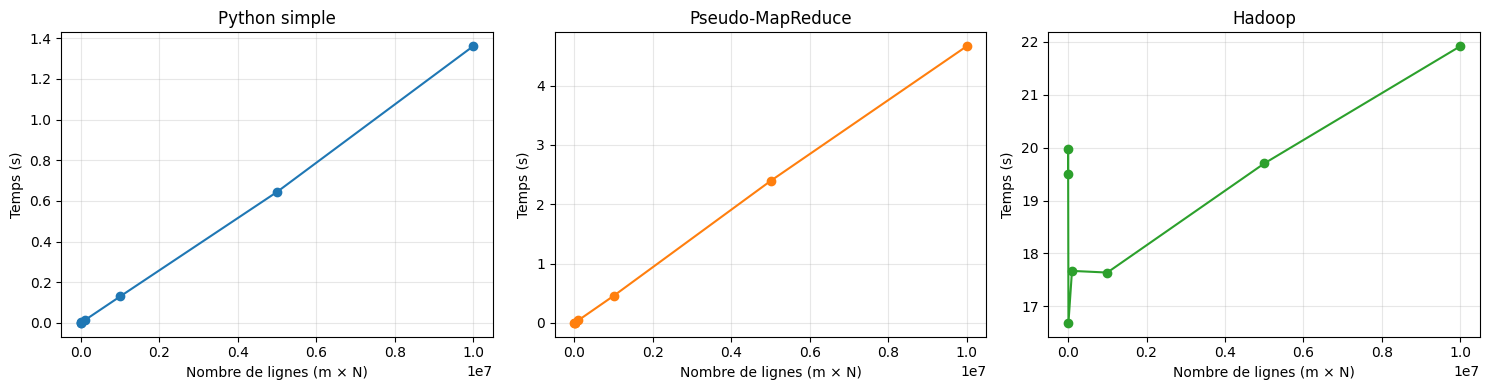

In [17]:
methodes = {"Python simple (s)": "tab:blue", "Pseudo-MapReduce (s)": "tab:orange"}
if HADOOPDISPONIBLE:
    methodes["Hadoop (s)"] = "tab:green"

fig, axes = plt.subplots(1, len(methodes), figsize=(5 * len(methodes), 4))
for ax, (col, couleur) in zip(axes, methodes.items()):
    ax.plot(df["lignes (m×N)"], df[col], "o-", color=couleur)
    ax.set_title(col.replace(" (s)", ""))
    ax.set_xlabel("Nombre de lignes (m × N)")
    ax.set_ylabel("Temps (s)")
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("courbesparmethode.png", dpi=150)
plt.show()

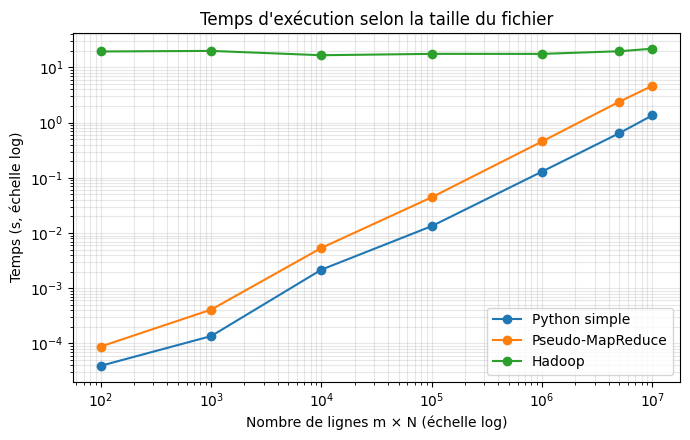

In [18]:
plt.figure(figsize=(7, 4.5))
for col, couleur in methodes.items():
    plt.plot(df["lignes (m×N)"], df[col], "o-", color=couleur, label=col.replace(" (s)", ""))
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Nombre de lignes m × N (échelle log)")
plt.ylabel("Temps (s, échelle log)")
plt.title("Temps d'exécution selon la taille du fichier")
plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.savefig("courbecomparaison.png", dpi=150)
plt.show()

## 8. Analyse

**Python simple.** Le temps est proportionnel au nombre de lignes (complexité O(n)) : environ 0,15 ms pour 100 lignes et 1,8 s pour 10 millions de lignes. C'est la méthode la plus rapide.

**Pseudo-MapReduce.** La complexité est la même (O(n)), mais la méthode est environ 3 fois plus lente (environ 5 s pour 10 millions de lignes), à cause des paires (mot, 1) créées puis stockées en mémoire avant le *reduce*.

**Hadoop MapReduce.** Le temps reste presque constant, autour de 20 secondes, quelle que soit la taille. Il s'agit surtout d'un coût fixe de démarrage (YARN, JVM, HDFS) et non du temps de calcul.

**Évolution de l'écart.** L'écart entre Hadoop et Python se réduit quand la taille augmente : à 10 millions de lignes, Hadoop n'est plus qu'environ 4 fois plus lent que la version pseudo-MapReduce. D'après les courbes, il deviendrait compétitif pour des volumes de plusieurs gigaoctets (extrapolation).



## 9. Version 4 : PySpark

In [15]:
os.environ["SPARK_LOCAL_IP"] = "127.0.0.1"
from pyspark.sql import SparkSession

spark = (SparkSession.builder
         .master("local[*]")
         .appName("comptemots")
         .config("spark.ui.showConsoleProgress", "false")
         .getOrCreate())
sc = spark.sparkContext
sc.setLogLevel("ERROR")


def compter_spark(fichier):
    chemin = "file://" + os.path.abspath(fichier)
    resultat = (sc.textFile(chemin)
                  .flatMap(lambda ligne: ligne.split())
                  .map(lambda mot: (mot, 1))
                  .reduceByKey(lambda a, b: a + b)
                  .collect())
    return dict(resultat)


res4 = compter_spark(SOURCE)
afficher(res4)

[Stage 0:>                                                          (0 + 2) / 2]

fleur      : 12
mer        : 10
soleil     : 9
chat       : 8
ciel       : 8
oiseau     : 8
voiture    : 8
chien      : 7
maison     : 7
lune       : 6
arbre      : 4
jardin     : 4
livre      : 3
montagne   : 3
route      : 3


In [24]:
print("Version de Spark      :", spark.version)
print("Cœurs du processeur   :", os.cpu_count())
print("Parallélisme de Spark :", sc.defaultParallelism)

tempsjob = []
for _ in range(5):
    debut = time.perf_counter()
    sc.parallelize([1]).count()
    tempsjob.append(time.perf_counter() - debut)

print(f"Coût fixe d'un job Spark : {sum(tempsjob) / len(tempsjob):.3f} s (moyenne sur 5 jobs)")

Version de Spark      : 3.5.9
Cœurs du processeur   : 16
Parallélisme de Spark : 16
Coût fixe d'un job Spark : 0.317 s (moyenne sur 5 jobs)


In [19]:
df = pd.read_csv("resultats.csv")

REPETITIONS = 3


def chrono(fonction, fichier, repetitions=REPETITIONS):
    temps = []
    for _ in range(repetitions):
        debut = time.perf_counter()
        fonction(fichier)
        temps.append(time.perf_counter() - debut)
    return sum(temps) / len(temps)



tempsspark = []
for m in df["m"]:
    fichier = os.path.join(DOSSIER, f"mots_m{m}.txt")
    if not os.path.exists(fichier):         
        dupliquer(SOURCE, m, fichier)
    tempsspark.append(chrono(compter_spark, fichier))
    print(f"m = {m:>7} terminé")

df["PySpark (s)"] = tempsspark
df.to_csv("resultats.csv", index=False)
df

m =       1 terminé
m =      10 terminé
m =     100 terminé
m =    1000 terminé


m =   10000 terminé


m =   50000 terminé


[Stage 42:>                                                         (0 + 2) / 2]

m =  100000 terminé


,m,lignes (m×N),taille (Mo),Python simple (s),Pseudo-MapReduce (s),Hadoop (s),PySpark (s)
0,1,100,0.000583,0.000039,0.000088,19.508123,0.301512
1,10,1000,0.005827,0.000136,0.000409,19.982875,0.287844
2,100,10000,0.058270,0.002169,0.005376,16.684334,0.243350
3,1000,100000,0.582695,0.013347,0.044503,17.668308,0.249905
4,10000,1000000,5.826950,0.130016,0.456773,17.636828,0.708853
5,50000,5000000,29.134750,0.644066,2.394294,19.701042,2.770546
6,100000,10000000,58.269501,1.360685,4.665990,21.920767,5.444487


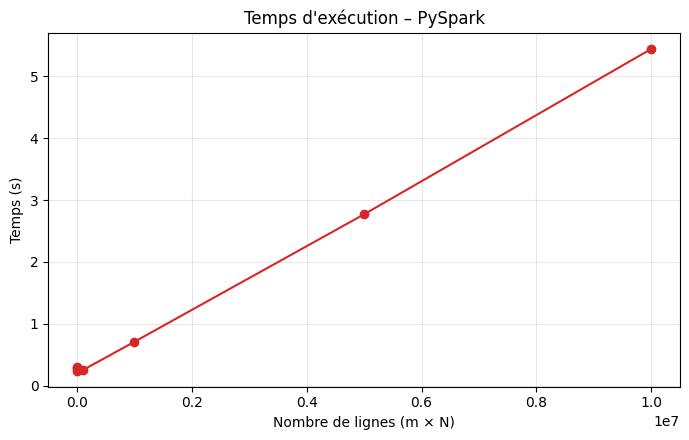

In [20]:
plt.figure(figsize=(7, 4.5))
plt.plot(df["lignes (m×N)"], df["PySpark (s)"], "o-", color="tab:red")
plt.title("Temps d'exécution – PySpark")
plt.xlabel("Nombre de lignes (m × N)")
plt.ylabel("Temps (s)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("courbepyspark.png", dpi=150)
plt.show()

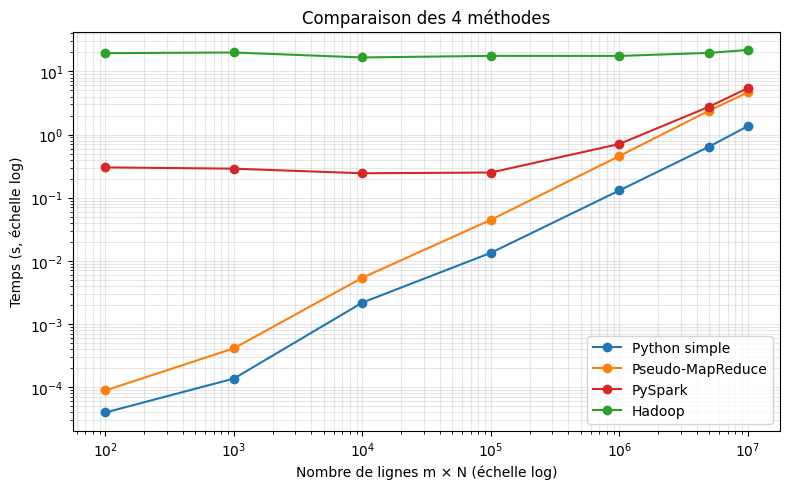

In [21]:
methodes = {"Python simple (s)": "tab:blue",
            "Pseudo-MapReduce (s)": "tab:orange",
            "PySpark (s)": "tab:red"}
if "Hadoop (s)" in df.columns:
    methodes["Hadoop (s)"] = "tab:green"

plt.figure(figsize=(8, 5))
for col, couleur in methodes.items():
    plt.plot(df["lignes (m×N)"], df[col], "o-", color=couleur, label=col.replace(" (s)", ""))
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Nombre de lignes m × N (échelle log)")
plt.ylabel("Temps (s, échelle log)")
plt.title("Comparaison des 4 méthodes")
plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.savefig("courbecomparaison.png", dpi=150)
plt.show()

## 9. Analyse
**PySpark.** Jusqu'à 100 000 lignes, le temps reste autour de 0,3 s, soit le temps d'un job Spark presque vide (0,317 s) : ce plateau correspond au coût fixe de Spark, et non au traitement des données. Le temps augmente ensuite avec la taille (environ 5,5 s pour 10 millions de lignes). PySpark reste plus lent que Python simple, car les fonctions lambda s'exécutent dans des processus Python séparés et le fichier n'est découpé qu'en 2 partitions, alors que la machine a 16 cœurs.

**Hadoop MapReduce.** Le temps reste presque constant, autour de 20 s : c'est surtout le coût de démarrage d'un job (YARN, JVM, HDFS).

**Spark face à Hadoop.** Spark garde les données en mémoire entre les étapes, alors que Hadoop les écrit sur le disque. Son coût fixe est environ 60 fois plus faible, et il reste environ 4 fois plus rapide à 10 millions de lignes.

**Évolution des écarts.** Plus le fichier est gros, plus les écarts se réduisent, car les coûts fixes pèsent de moins en moins face au temps de calcul.

**Limites.** Les mesures sont faites sur une seule machine, avec au plus 60 Mo de données, alors que Spark et Hadoop sont conçus pour de très gros volumes répartis sur plusieurs machines.

## 10. Conclusion
Ce TP a comparé quatre méthodes de comptage de mots sur des fichiers de 100 à 10 millions de lignes. Les quatre donnent exactement les mêmes résultats.

- **Python simple** est la plus rapide (environ 1,4 s pour 10 millions de lignes).
- **Pseudo-MapReduce** illustre bien le modèle *map / shuffle / reduce*, mais elle est environ 3 fois plus lente.
- **PySpark** a un faible coût fixe (environ 0,3 s) et reste environ 4 fois plus rapide que Hadoop.
- **Hadoop** est pénalisé par un coût de démarrage d'environ 20 s.

Le choix de l'outil dépend donc du volume de données : Python suffit pour quelques millions de lignes, tandis que Spark est plus adapté aux très gros volumes répartis sur un cluster.